# Training Results Viewer (macro evaluation)

This notebook allows you to load and visualize the results of finetuning LaBraM on the EEG dataset. It generates figures based on averaged results across datasets, allowing to compare the general performance of one or more models.

## Setup

In [1]:
import numpy as np
from IPython.display import display
from pathlib import Path
import json
import core.settings as settings
import core.utils as core_utils
import matplotlib.pyplot as plt
import os
import core.io as io
from ipywidgets import widgets
from libs.labram import utils
from libs.labram import engine_for_finetuning as engine
from torch import utils as torch_utils
import torch

from core.architectures import EEGAutoencoder, EEGSpectralDecoder
from core.datasets import KFoldSplitter

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir('..')

def save_button(fig, save_dir: Path, default_name="untitled"):
    name_input = widgets.Text(value=default_name, description='Filename:', placeholder='untitled')

    save_button_comp = widgets.Button(description="Save Figure")
    output_comp = widgets.Output()
    def on_save_clicked(b):
        with output_comp:
            output_comp.clear_output()
            filename = name_input.value.strip() or default_name
            if not filename.endswith(".png"):
                filename += ".png"
            save_dir.mkdir(parents=True, exist_ok=True)

            try:
                save_path = save_dir / filename
                fig.savefig(save_path, dpi=300, bbox_inches='tight')
                print(f"Figure saved to: {save_path}")
            except Exception as e:
                print(f"Error saving figure: {e}")
    save_button_comp.on_click(on_save_clicked)
    display(widgets.VBox([widgets.HBox([name_input]), save_button_comp, output_comp]))

def show_delta(ax, epoch, val1, val2):
    delta = np.absolute(val2 - val1)
    midpoint = (val1 + val2) / 2
    ax.plot(epoch, val1, 'ko', markersize=4)
    ax.plot(epoch, val2, 'ko', markersize=4)

    ax.vlines(x=epoch, ymin=min(val1, val2), ymax=max(val1, val2), color='black', linestyle='--')
    ax.annotate(
        f"$\Delta$: {delta:.4f}",
        xy=(epoch, midpoint),
        xytext=(10, 0),
        textcoords='offset points',
        va='center',
        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='black', alpha=0.8),
        color='black',
        fontsize=10
    )



## Plotting training and validation losses across epochs

ValueError: x, y, and format string must not be None

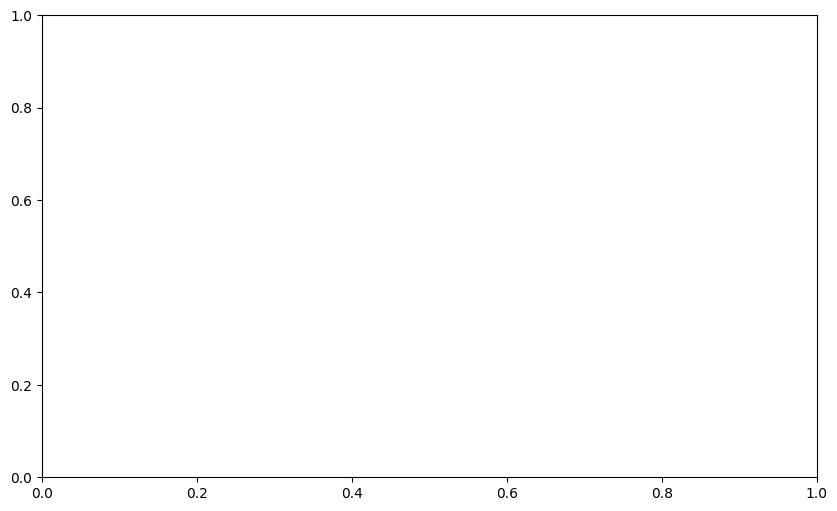

In [2]:
model_name = "fixed_wavelet_huber"

model_data = io.load_model_log_data(settings.FINETUNE_OUTPUT_DIR, model_name=model_name)
epochs = np.array([entry["epoch"] for entry in next(iter(model_data.values())) if "val_r2" in entry])
avg_metrics = core_utils.avg_metrics_over_folds(model_data = model_data, metrics=["train_r2", "val_r2"])

avg_train = avg_metrics["train_r2"]
avg_val = avg_metrics["val_r2"]

# plot training and validation losses across epochs
fig = plt.figure(figsize=(10, 6))
plt.plot(epochs, avg_train, label="Train R2")
plt.plot(epochs, avg_val, label="Validation R2")
plt.xlabel("Epoch")
plt.ylabel("R2 Score")
plt.title(f"Training and Validation R2 Scores for {model_name}")
plt.legend()
plt.grid()
save_button(fig, save_dir=settings.PLOT_MACRO/"train_val", default_name=model_name)
i = np.argmax(avg_val)
max_epoch = epochs[i]

show_delta(fig.gca(), max_epoch, avg_train[i], avg_val[i])
plt.show()

## Plotting val performance of multiple models across epochs

In [1]:
model_names = ["fixed_wavelet_huber", "huber_0929", "unbalanced_huber","balanced_huber"]
#model_names = ["wavelet_5e-3_pre", "wavelet_5e-3_scratch"]
#model_names= ["wavelet_1e-3_scratch", "wavelet_5e-3_scratch", "wavelet_5e-4_scratch"]
#model_names = ["wavelet_1e-3_pre", "wavelet_1e-3_scratch", "wavelet_5e-3_pre", "wavelet_5e-3_scratch", "wavelet_5e-4_pre", "wavelet_5e-4_scratch"]
#compare_diff = [("wavelet_5e-3_pre", "wavelet_5e-4_pre")]
compare_diff = []
to = 80

avg_vals, val_epochs = {}, {}
for model_name in model_names:
    model_data = io.load_model_log_data(settings.FINETUNE_OUTPUT_DIR, model_name=model_name)
    avg_metrics = core_utils.avg_metrics_over_folds(model_data = model_data, metrics=["val_r2"])
    val_epochs[model_name] = np.array([entry["epoch"] for entry in next(iter(model_data.values())) if "val_r2" in entry])
    avg_vals[model_name] = avg_metrics["val_r2"]

#plot validation losses across epochs on one line graph for all models
fig = plt.figure(figsize=(10, 6))
for model_name in model_names:
    if "pre" in model_name:
        label = f"{model_name} (pretrained)"
        linestyle = "--"
    else:
        label = model_name
        linestyle = "-"
    keep = val_epochs[model_name] < to

    plt.plot(val_epochs[model_name][keep], avg_vals[model_name][keep], label=label, linestyle=linestyle)

for model_a, model_b in compare_diff:
    val_a = avg_vals[model_a]
    val_b = avg_vals[model_b]
    i = min(len(val_a), len(val_b)) - 1
    show_delta(fig.gca(), val_epochs[model_a][i], val_a[i], val_b[i])

plt.xlabel("Epoch")
plt.ylabel("Validation R2 Score")
plt.title("Validation R2 Scores Across Epochs for Multiple Models")
plt.legend()
plt.grid()
save_button(fig, save_dir=settings.PLOT_MACRO/"val_multiple")
plt.show()


NameError: name 'io' is not defined